# Adoção do Pix nos municípios do Brasil

**Pergunta:** o Pix chegou a todo o Brasil no mesmo ritmo, ou há regiões que seguem atrás em usuários e em uso por pessoa?

**Dados:** transações Pix por município do Banco Central, de novembro de 2020 a outubro de 2026, usuários cadastrados no DICT e população do IBGE.

**Principais medidas:**

- **Pagador ativo:** pessoa física que fez ao menos um Pix no mês.
- **Penetração:** pagadores ativos divididos pela população.
- **Taxa de ativação:** pagadores ativos divididos pelos usuários cadastrados.
- **Frequência:** Pix pagos por pagador ativo no mês.
- **Valor médio:** valor de cada Pix, em reais nominais.

## 1. Preparação

A primeira célula roda o pipeline ETL. Ele usa os dados de `dados/brutos`, confere a qualidade e recria o banco SQLite. As consultas ficam em `sql/`.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "etl")
import pipeline

banco = pipeline.executar()
conexao = sqlite3.connect(banco)


def consultar(nome):
    """Roda uma consulta da pasta sql/ e devolve um DataFrame."""
    return pd.read_sql(Path("sql", f"{nome}.sql").read_text(encoding="utf-8"), conexao)


def para_data(ano_mes):
    return pd.to_datetime(ano_mes.astype(str), format="%Y%m")


def pct(valor, casas=1):
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor, casas=1):
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


pd.options.display.float_format = "{:,.4f}".format

9 testes de qualidade aprovados
401.019 linhas de Pix gravadas em pix.db


In [2]:
TINTA = "#0b0b0b"
TINTA_FRACA = "#52514e"
GRADE = "#e8e7e3"
SUPERFICIE = "#fcfcfb"
FONTE = "Fontes: Banco Central (dados abertos do Pix) e IBGE"

# A cor acompanha a região em todos os gráficos.
COR_REGIAO = {
    "Sudeste": "#2a78d6",
    "Nordeste": "#eb6834",
    "Norte": "#1baf7a",
    "Centro-Oeste": "#eda100",
    "Sul": "#e87ba4",
}

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TINTA_FRACA,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TINTA_FRACA,
    "ytick.color": TINTA_FRACA,
    "xtick.bottom": False,
    "ytick.left": False,
    "font.size": 11,
    "savefig.dpi": 160,
})


def titular(fig, titulo, subtitulo):
    fig.text(0.02, 0.975, titulo, fontsize=15, fontweight="bold", color=TINTA, va="top")
    fig.text(0.02, 0.915, subtitulo, fontsize=11, color=TINTA_FRACA, va="top")
    fig.text(0.02, 0.015, FONTE, fontsize=9, color=TINTA_FRACA)


def espalhar(valores, distancia):
    """Afasta os rótulos do fim das linhas para eles não se sobreporem."""
    ordem = sorted(valores, key=valores.get)
    posicoes = {}
    anterior = None
    for chave in ordem:
        posicao = valores[chave]
        if anterior is not None:
            posicao = max(posicao, anterior + distancia)
        posicoes[chave] = posicao
        anterior = posicao
    excesso = (posicoes[ordem[-1]] - valores[ordem[-1]]) / 2
    return {chave: posicao - excesso for chave, posicao in posicoes.items()}

## 2. Conferência da base

O pipeline interrompe a execução se algum teste falhar. Aqui ficam os testes que vale olhar com calma.

In [3]:
conferencia = pd.read_sql(
    """
    SELECT
        COUNT(DISTINCT ano_mes) AS meses,
        MIN(ano_mes) AS primeiro_mes,
        MAX(ano_mes) AS ultimo_mes,
        COUNT(*) AS linhas,
        COUNT(DISTINCT CASE WHEN municipio_ibge <> 0 THEN municipio_ibge END) AS municipios
    FROM pix_municipio_mes
    """,
    conexao,
)
conferencia

,meses,primeiro_mes,ultimo_mes,linhas,municipios
0,72,202011,202610,401019,5571


**Conciliação:** no total do país, todo Pix pago precisa ter sido recebido. Esse teste compara os dois lados, em quantidade e em valor, para cada mês. A diferença aceita é de 0,01% do valor.

In [4]:
conciliacao = consultar("02_conciliacao")
conciliacao["parcela_vl"] = conciliacao["diferenca_vl"].abs() / conciliacao["vl_pago"]
divergentes = conciliacao[
    (conciliacao["diferenca_qt"] != 0) | (conciliacao["diferenca_vl"].abs() > 0.01)
]
print("Meses que fecham exatamente:", len(conciliacao) - len(divergentes), "de", len(conciliacao))
pd.options.display.float_format = "{:,.6f}".format
display(divergentes[["ano_mes", "diferenca_qt", "diferenca_vl", "parcela_vl"]])
pd.options.display.float_format = "{:,.4f}".format

Meses que fecham exatamente: 67 de 72


,ano_mes,diferenca_qt,diferenca_vl,parcela_vl
3,202102,1,"25,378.000000",0.000000
8,202107,-2,-324.100000,0.000000
12,202111,-819,"7,491,090.330000",0.000014
57,202508,502,"1,205,108.810000",0.000000
58,202509,627,"1,124,436.090000",0.000000


Os cinco meses com diferença ficam muito abaixo do limite, e as diferenças estão na própria fonte. O teste foi conferido com uma nova consulta à API.

**Municípios com série incompleta:** três municípios só aparecem em 2025. A base começa com 5.568 municípios e termina com 5.571.

In [5]:
pd.read_sql(
    """
    SELECT m.nome, m.uf, MIN(p.ano_mes) AS primeiro_mes, COUNT(*) AS meses
    FROM pix_municipio_mes AS p
    JOIN municipio AS m USING (municipio_ibge)
    WHERE p.municipio_ibge <> 0
    GROUP BY p.municipio_ibge
    HAVING COUNT(*) < 72
    """,
    conexao,
)

,nome,uf,primeiro_mes,meses
0,Campo Grande,RN,202504,19
1,Januário Cicco,RN,202504,19
2,Boa Esperança Do Norte,MT,202510,13


**Linha sem município:** o Banco Central guarda em uma linha à parte os Pix sem município identificado. Ela entra nos totais do país, mas não nas contas por região.

In [6]:
pd.read_sql(
    """
    SELECT
        ano_mes,
        SUM(CASE WHEN municipio_ibge = 0 THEN pagadores_pf ELSE 0 END) AS sem_municipio,
        1.0 * SUM(CASE WHEN municipio_ibge = 0 THEN pagadores_pf ELSE 0 END)
            / SUM(pagadores_pf) AS parcela
    FROM pix_municipio_mes
    WHERE ano_mes = 202610
    """,
    conexao,
)

,ano_mes,sem_municipio,parcela
0,202610,188857,0.0013


**Municípios atípicos:** uma penetração acima de 100% não é possível se a contagem for de moradores. Pacaraima (RR), com 24 mil moradores, tem 179 mil pagadores. O município fica na fronteira com a Venezuela, mas esta base não permite afirmar a causa.

In [7]:
atipicos = consultar("10_municipios_atipicos")
atipicos

,nome,uf,populacao,pagadores_pf,penetracao,primeiro_mes
0,Pacaraima,RR,24132,179432,7.4354,202011
1,Águas De São Pedro,SP,2933,3252,1.1088,202011
2,Mocajuba,PA,28982,29139,1.0054,202011
3,Urucuia,MG,18727,5585,0.2982,202011
4,Ipixuna,AM,25792,7560,0.2931,202011
5,Aroeiras Do Itaim,PI,2787,808,0.2899,202011
6,Balbinos,SP,3975,1131,0.2845,202011
7,Cumaru Do Norte,PA,15354,4349,0.2832,202011
8,Amajari,RR,16647,4453,0.2675,202011
9,Matões Do Norte,MA,18087,4673,0.2584,202011


In [8]:
historico_pacaraima = pd.read_sql(
    """
    SELECT p.ano_mes, p.pagadores_pf, 1.0 * p.pagadores_pf / m.populacao AS penetracao
    FROM pix_municipio_mes AS p
    JOIN municipio AS m USING (municipio_ibge)
    WHERE p.municipio_ibge = 1400456
      AND p.ano_mes % 100 = 10
    ORDER BY p.ano_mes
    """,
    conexao,
)
historico_pacaraima

,ano_mes,pagadores_pf,penetracao
0,202110,27778,1.1511
1,202210,51647,2.1402
2,202310,82864,3.4338
3,202410,117146,4.8544
4,202510,150231,6.2254
5,202610,179432,7.4354


## 3. Funil nacional

Os cadastrados são os usuários com chave Pix. A taxa de ativação é uma aproximação, porque é possível usar o Pix sem ter chave.

In [9]:
funil = consultar("03_funil_nacional")
funil["data"] = para_data(funil["ano_mes"])
funil[funil["ano_mes"].isin([202011, 202110, 202210, 202310, 202410, 202510, 202610])][
    ["ano_mes", "cadastrados", "pagadores", "taxa_ativacao", "penetracao", "frequencia", "valor_medio"]
]

,ano_mes,cadastrados,pagadores,taxa_ativacao,penetracao,frequencia,valor_medio
0,202011,38741572,9597668,0.2477,0.0448,2.6423,503.0483
11,202110,105243893,76698740,0.7288,0.3581,11.5291,295.2573
23,202210,127832479,100428341,0.7856,0.4688,18.4386,238.7011
35,202310,142785942,118061725,0.8268,0.5511,26.8231,195.2511
47,202410,154778329,131995671,0.8528,0.6162,33.9726,193.0859
59,202510,161755431,140234820,0.8670,0.6547,38.5454,187.9928
71,202610,168816010,148407879,0.8791,0.6928,42.5671,186.1213


## 4. O que puxou o crescimento

O valor movimentado é `pagadores x frequência x valor médio`. Comparar outubro com outubro evita o efeito das datas sazonais.

In [10]:
crescimento = consultar("04_crescimento_anual")
crescimento

,ano_mes,pagadores,frequencia,valor_medio,valor,razao_pagadores,razao_frequencia,razao_valor_medio,razao_valor
0,202110,76698740,11.5291,295.2573,"261,085,483,467.5800",NaN,NaN,NaN,NaN
1,202210,100428341,18.4386,238.7011,"442,017,347,536.2600",1.3094,1.5993,0.8085,1.6930
2,202310,118061725,26.8231,195.2511,"618,317,306,831.1000",1.1756,1.4547,0.8180,1.3989
3,202410,131995671,33.9726,193.0859,"865,843,364,738.4700",1.1180,1.2665,0.9889,1.4003
4,202510,140234820,38.5454,187.9928,"1,016,178,855,397.4500",1.0624,1.1346,0.9736,1.1736
5,202610,148407879,42.5671,186.1213,"1,175,783,377,843.1499",1.0583,1.1043,0.9900,1.1571


In [11]:
primeiro, ultimo = crescimento.iloc[0], crescimento.iloc[-1]
multiplos = pd.Series({
    "Pagadores": ultimo["pagadores"] / primeiro["pagadores"],
    "Frequência": ultimo["frequencia"] / primeiro["frequencia"],
    "Valor médio": ultimo["valor_medio"] / primeiro["valor_medio"],
    "Valor total": ultimo["valor"] / primeiro["valor"],
})
print("Conferência (pagadores x frequência x valor médio):",
      round(multiplos.iloc[:3].prod(), 4), "=", round(multiplos.iloc[3], 4))
multiplos

Conferência (pagadores x frequência x valor médio): 4.5034 = 4.5034


Pagadores     1.9349
Frequência    3.6922
Valor médio   0.6304
Valor total   4.5034
dtype: float64

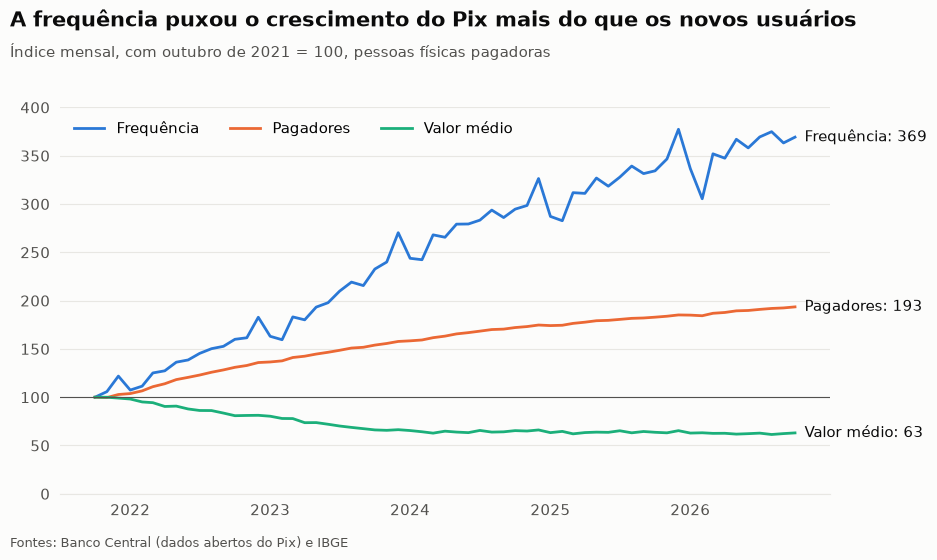

In [12]:
base = funil[funil["ano_mes"] == 202110].iloc[0]
indice = funil[funil["ano_mes"] >= 202110].copy()
series = {"Frequência": "frequencia", "Pagadores": "pagadores", "Valor médio": "valor_medio"}
cores = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.07, right=0.84, top=0.80, bottom=0.11)
for (nome, coluna), cor in zip(series.items(), cores):
    y = indice[coluna] / base[coluna] * 100
    ax.plot(indice["data"], y, color=cor, linewidth=2, label=nome)
    ax.text(indice["data"].iloc[-1] + pd.Timedelta(days=25), y.iloc[-1],
            f"{nome}: {num(y.iloc[-1], 0)}", color=TINTA, va="center")
ax.axhline(100, color=TINTA_FRACA, linewidth=0.8)
ax.set_ylim(0, 400)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", frameon=False, ncols=3)
titular(fig, "A frequência puxou o crescimento do Pix mais do que os novos usuários",
        "Índice mensal, com outubro de 2021 = 100, pessoas físicas pagadoras")
fig.savefig("imagens/crescimento-indice.png", facecolor=SUPERFICIE)
plt.show()

## 5. Penetração por região

In [13]:
regioes = consultar("05_penetracao_regiao")
regioes["data"] = para_data(regioes["ano_mes"])
tabela_regioes = regioes.pivot(index="ano_mes", columns="regiao", values="penetracao")
distancia = regioes.drop_duplicates("ano_mes").set_index("ano_mes")[["diferenca", "razao"]]
tabela_regioes.loc[[202101, 202301, 202610]]

regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
ano_mes,,,,,
202101,0.1675,0.0979,0.1047,0.1752,0.1398
202301,0.5031,0.4372,0.4439,0.5324,0.4748
202610,0.6938,0.6532,0.6682,0.7265,0.6780


In [14]:
distancia.loc[[202101, 202201, 202301, 202401, 202501, 202610]]

,diferenca,razao
ano_mes,,
202101,0.0773,1.7896
202201,0.1128,1.3669
202301,0.0953,1.2179
202401,0.0836,1.1599
202501,0.0787,1.1352
202610,0.0734,1.1123


In [15]:
maior_distancia = distancia["diferenca"].idxmax()
print("Maior distância entre regiões:", maior_distancia, pct(distancia["diferenca"].max()))
marcos = consultar("06_marco_50_por_cento")
marcos

Maior distância entre regiões: 202111 11,6%


,regiao,mes_marco,penetracao
0,Sudeste,202209,0.5043
1,Centro-Oeste,202212,0.5018
2,Sul,202305,0.5035
3,Nordeste,202310,0.5054
4,Norte,202310,0.5083


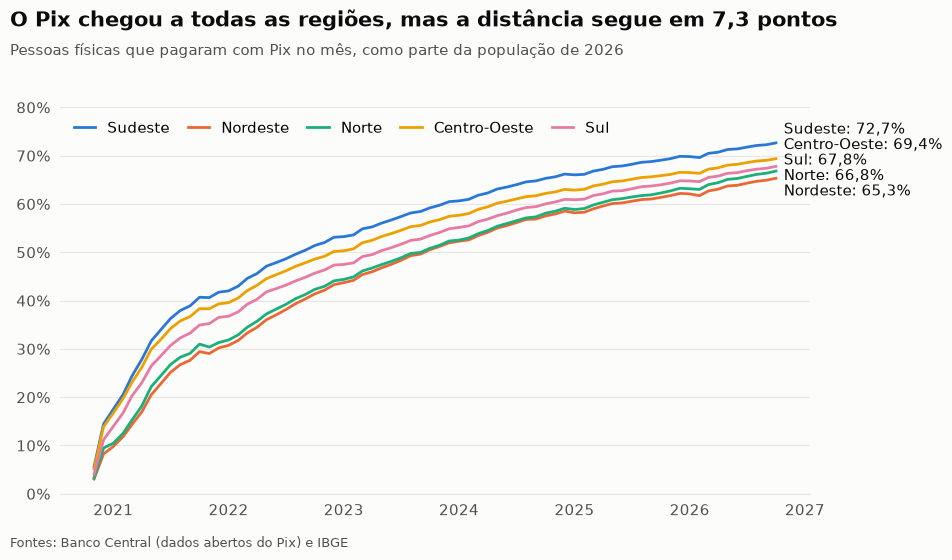

In [16]:
finais = regioes[regioes["ano_mes"] == regioes["ano_mes"].max()].set_index("regiao")["penetracao"]
rotulos = espalhar(finais.to_dict(), 0.032)

fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.07, right=0.82, top=0.80, bottom=0.11)
for regiao, cor in COR_REGIAO.items():
    dados = regioes[regioes["regiao"] == regiao]
    ax.plot(dados["data"], dados["penetracao"], color=cor, linewidth=2, label=regiao)
    ax.text(dados["data"].iloc[-1] + pd.Timedelta(days=25), rotulos[regiao],
            f"{regiao}: {pct(finais[regiao])}", color=TINTA, va="center")
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(lambda valor, _: f"{valor * 100:.0f}%")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", frameon=False, ncols=5, columnspacing=1.2, handlelength=1.4)
titular(fig, f"O Pix chegou a todas as regiões, mas a distância segue em {num(distancia.loc[202610, 'diferenca'] * 100)} pontos",
        "Pessoas físicas que pagaram com Pix no mês, como parte da população de 2026")
fig.savefig("imagens/penetracao-regioes.png", facecolor=SUPERFICIE)
plt.show()

## 6. Distância entre municípios

Aqui cada município vale um ponto, sem peso pela população. O percentil 10 mostra os municípios mais atrasados, e o percentil 90, os mais avançados.

In [17]:
dispersao = consultar("09_dispersao_municipios")
dispersao["data"] = para_data(dispersao["ano_mes"])
dispersao["diferenca"] = dispersao["p90"] - dispersao["p10"]
dispersao["razao"] = dispersao["p90"] / dispersao["p10"]
dispersao[dispersao["ano_mes"].isin([202101, 202201, 202301, 202401, 202501, 202610])]

,ano_mes,p10,p50,p90,data,diferenca,razao
2,202101,0.0338,0.0629,0.1161,2021-01-01,0.0823,3.4341
14,202201,0.1738,0.2566,0.3582,2022-01-01,0.1844,2.0608
26,202301,0.2862,0.3811,0.4897,2023-01-01,0.2034,1.7107
38,202401,0.3689,0.4688,0.5774,2024-01-01,0.2085,1.5653
50,202501,0.4272,0.5303,0.6365,2025-01-01,0.2094,1.4901
71,202610,0.5046,0.6076,0.7110,2026-10-01,0.2064,1.4090


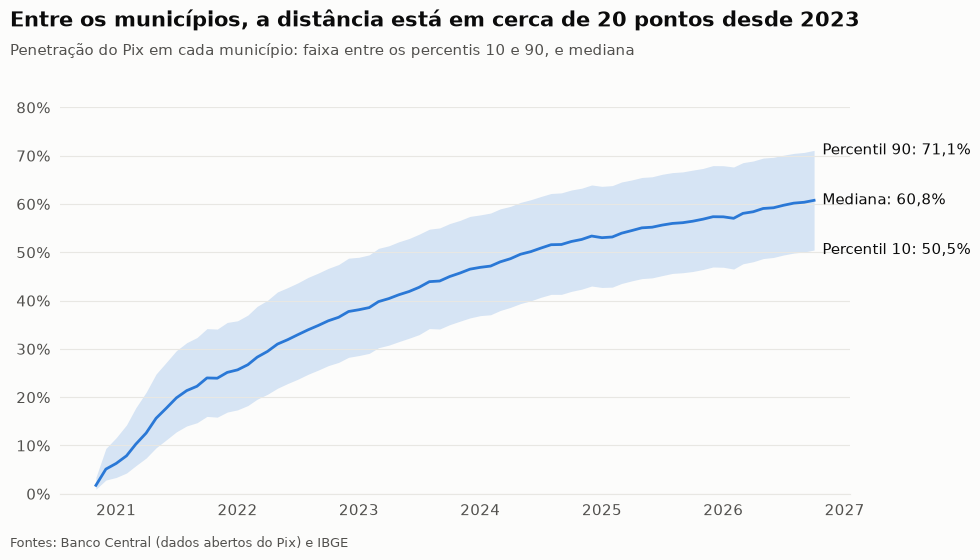

In [18]:
fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(left=0.07, right=0.86, top=0.80, bottom=0.11)
ax.fill_between(dispersao["data"], dispersao["p10"], dispersao["p90"], color="#2a78d6", alpha=0.18, linewidth=0)
ax.plot(dispersao["data"], dispersao["p50"], color="#2a78d6", linewidth=2)
fim = dispersao.iloc[-1]
for rotulo, coluna in {"Percentil 90": "p90", "Mediana": "p50", "Percentil 10": "p10"}.items():
    ax.text(fim["data"] + pd.Timedelta(days=25), fim[coluna],
            f"{rotulo}: {pct(fim[coluna])}", color=TINTA, va="center")
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(lambda valor, _: f"{valor * 100:.0f}%")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
titular(fig, "Entre os municípios, a distância está em cerca de 20 pontos desde 2023",
        "Penetração do Pix em cada município: faixa entre os percentis 10 e 90, e mediana")
fig.savefig("imagens/dispersao-municipios.png", facecolor=SUPERFICIE)
plt.show()

## 7. Uso por pessoa

A penetração mostra quantos usam. A frequência mostra o quanto usam, e aqui a ordem das regiões quase se inverte.

In [19]:
uso = consultar("07_uso_por_regiao")
uso["penetracao"] = uso["regiao"].map(finais)
uso

,regiao,pagadores,frequencia,valor_medio,valor_por_pagador,penetracao
0,Norte,12649019,54.3600,144.8896,"7,876.2046",0.6682
1,Nordeste,37470071,47.5949,148.6126,"7,073.2067",0.6532
2,Centro-Oeste,12072774,43.1338,237.4449,"10,241.9003",0.6938
3,Sudeste,64672713,39.7957,203.5486,"8,100.3687",0.7265
4,Sul,21354445,35.0402,216.2732,"7,578.2552",0.6780


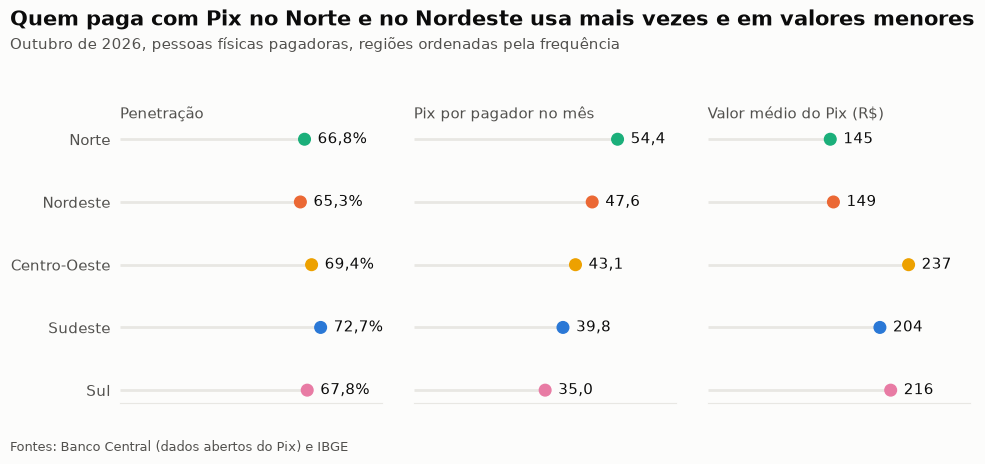

In [20]:
ordem = uso.sort_values("frequencia")
paineis = [
    ("penetracao", "Penetração", lambda valor: pct(valor), 0.95),
    ("frequencia", "Pix por pagador no mês", lambda valor: num(valor), 70),
    ("valor_medio", "Valor médio do Pix (R$)", lambda valor: num(valor, 0), 310),
]

fig, eixos = plt.subplots(1, 3, figsize=(10, 4.6), sharey=True)
fig.subplots_adjust(left=0.13, right=0.98, top=0.72, bottom=0.12, wspace=0.12)
for ax, (coluna, nome, formato, limite) in zip(eixos, paineis):
    cores_regiao = ordem["regiao"].map(COR_REGIAO)
    ax.hlines(ordem["regiao"], 0, ordem[coluna], color=GRADE, linewidth=2)
    ax.scatter(ordem[coluna], ordem["regiao"], color=cores_regiao, s=70, zorder=3)
    for _, linha in ordem.iterrows():
        ax.text(linha[coluna] + limite * 0.05, linha["regiao"], formato(linha[coluna]),
                color=TINTA, va="center")
    ax.set_xlim(0, limite)
    ax.set_title(nome, loc="left", fontsize=11, color=TINTA_FRACA)
    ax.grid(False)
    ax.set_xticks([])
titular(fig, "Quem paga com Pix no Norte e no Nordeste usa mais vezes e em valores menores",
        "Outubro de 2026, pessoas físicas pagadoras, regiões ordenadas pela frequência")
fig.savefig("imagens/uso-por-regiao.png", facecolor=SUPERFICIE)
plt.show()

## 8. Porte do município

In [21]:
porte = consultar("08_porte")
porte

,faixa_porte,municipios,populacao,penetracao,frequencia,valor_medio
0,Até 20 mil,3816,31968788,0.5944,37.3102,176.7162
1,20 a 100 mil,1417,57340007,0.6285,40.9036,175.5447
2,100 a 500 mil,289,58395565,0.7048,43.5483,182.7910
3,Mais de 500 mil,49,66507591,0.7821,44.9491,197.7226


## 9. Teste de sensibilidade

A conclusão depende da forma de medir? São dois testes: tirar Pacaraima e usar só adultos no denominador. Os adultos são estimados com a parcela de pessoas de 18 anos ou mais em cada UF no Censo 2022.

In [22]:
ranking = consultar("11_ranking_uf")
ranking.head(6)

,uf,pagadores,populacao,com_pacaraima,sem_pacaraima,rank_com,rank_sem,adultos_sem_pacaraima
0,DF,2426661,3009996,0.8062,0.8062,2,1,1.0512
1,SP,35020592,46179008,0.7584,0.7584,3,2,0.9698
2,AP,593049,809953,0.7322,0.7322,4,3,1.0850
3,RJ,12551503,17225410,0.7287,0.7287,5,4,0.9286
4,RR,704119,761012,0.9252,0.7120,1,5,1.0881
5,RO,1240569,1757338,0.7059,0.7059,6,6,0.9631


In [23]:
acima_de_100 = ranking[ranking["adultos_sem_pacaraima"] > 1]["uf"].tolist()
print("UFs acima de 100% entre adultos:", acima_de_100)
sensibilidade = consultar("13_sensibilidade_regiao")
sensibilidade

UFs acima de 100% entre adultos: ['DF', 'AP', 'RR']


,regiao,penetracao,sem_pacaraima,parcela_adulta,adultos_sem_pacaraima,posicao_populacao,posicao_adultos
0,Sudeste,0.7265,0.7265,0.7813,0.9299,1,2
1,Centro-Oeste,0.6938,0.6938,0.7478,0.9278,2,3
2,Sul,0.6780,0.6780,0.7773,0.8722,3,5
3,Norte,0.6682,0.6596,0.6941,0.9502,4,1
4,Nordeste,0.6532,0.6532,0.7420,0.8802,5,4


Com a população total, o Sudeste lidera e o Nordeste é o último. Entre adultos, o Norte lidera, porque tem a menor parcela de adultos, e o Sul é o último. A taxa passa de 100% em três UFs, então ela serve para comparar as regiões, não como uma parcela exata. Menores de 18 anos podem pagar com Pix, e um pagador pode não morar no município em que aparece.

## 10. De transferência a pagamento

A parcela de Pix recebida por empresas mostra se o Pix ficou mais próximo de um meio de pagamento.

In [24]:
recebedores = consultar("12_recebedores_pj")
recebedores[recebedores["ano_mes"].isin([202011, 202201, 202301, 202401, 202501, 202601, 202610])]

,ano_mes,parcela_pj
0,202011,0.0751
14,202201,0.2072
26,202301,0.2919
38,202401,0.4123
50,202501,0.4568
62,202601,0.5023
71,202610,0.5003


## 11. Números do README

Esta célula reúne os números citados no `README.md`, para que cada um possa ser conferido com uma saída real.

In [25]:
f_ini = funil.iloc[0]
f_fim = funil.iloc[-1]
reg_fim = distancia.loc[202610]
reg_ini = distancia.loc[202101]
d_ini = dispersao[dispersao["ano_mes"] == 202101].iloc[0]
d_jan23 = dispersao[dispersao["ano_mes"] == 202301].iloc[0]
d_fim = dispersao.iloc[-1]
rr = ranking[ranking["uf"] == "RR"].iloc[0]
pac = atipicos[atipicos["nome"] == "Pacaraima"].iloc[0]
pac_outubro = historico_pacaraima.set_index("ano_mes")

print("Conciliação:", len(conciliacao) - len(divergentes), "de", len(conciliacao),
      "| maior diferença:", num(conciliacao["parcela_vl"].max() * 100, 4) + "%",
      "| em reais:", num(conciliacao["diferenca_vl"].abs().max(), 0))
print("Pagadores:", num(f_ini["pagadores"] / 1e6), "->", num(f_fim["pagadores"] / 1e6), "milhões")
print("Penetração nacional:", pct(f_fim["penetracao"]))
print("Ativação:", pct(f_ini["taxa_ativacao"]), "->", pct(f_fim["taxa_ativacao"]))
print("Frequência:", num(f_ini["frequencia"]), "->", num(f_fim["frequencia"]))
print("Valor médio:", num(f_ini["valor_medio"], 0), "->", num(f_fim["valor_medio"], 0))
print("Valor do mês (R$ tri):", num(f_fim["valor"] / 1e12, 2))
print("Múltiplos 2021-2026:", {k: num(v, 2) for k, v in multiplos.items()})
print("Pagadores ao ano:", [pct(v - 1) for v in crescimento["razao_pagadores"].dropna()])
print("Frequência ao ano:", [pct(v - 1) for v in crescimento["razao_frequencia"].dropna()])
print("Razão entre regiões:", num(reg_ini["razao"], 2), "->", num(reg_fim["razao"], 2))
print("Distância entre regiões:", pct(reg_ini["diferenca"]), "->", pct(reg_fim["diferenca"]),
      "| máxima:", maior_distancia, pct(distancia["diferenca"].max()))
print("Marco de 50%:", dict(zip(marcos["regiao"], marcos["mes_marco"])))
print("P90-P10:", pct(d_ini["diferenca"]), pct(d_jan23["diferenca"]), pct(d_fim["diferenca"]))
print("P90/P10:", num(d_ini["razao"], 2), "->", num(d_fim["razao"], 2))
print("Porte:", dict(zip(porte["faixa_porte"], porte["penetracao"].map(pct))))
print("Frequência por porte:", dict(zip(porte["faixa_porte"], porte["frequencia"].map(num))))
print("Pacaraima:", int(pac["pagadores_pf"]), "de", int(pac["populacao"]), "=", num(pac["penetracao"], 1), "vezes")
print("Pacaraima, outubro de 2021:", num(pac_outubro.loc[202110, "penetracao"], 2), "vezes")
print("RR:", pct(rr["com_pacaraima"]), "->", pct(rr["sem_pacaraima"]),
      "| posição:", rr["rank_com"], "->", rr["rank_sem"])
print("Sensibilidade:", dict(zip(sensibilidade["regiao"], sensibilidade["adultos_sem_pacaraima"].map(pct))))
print("Parcela adulta:", dict(zip(sensibilidade["regiao"], sensibilidade["parcela_adulta"].map(pct))))
print("Cadastrados:", num(f_fim["cadastrados"] / 1e6), "milhões")
resumo = uso.merge(sensibilidade, on="regiao").merge(marcos, on="regiao")
for _, linha in resumo.sort_values("penetracao_y", ascending=False).iterrows():
    print(linha["regiao"], pct(linha["penetracao_y"]), pct(linha["adultos_sem_pacaraima"]),
          num(linha["frequencia"]), num(linha["valor_medio"], 0), linha["mes_marco"])
print("Parcela PJ:", pct(recebedores.iloc[0]["parcela_pj"]), "->", pct(recebedores.iloc[-1]["parcela_pj"]))

Conciliação: 67 de 72 | maior diferença: 0,0014% | em reais: 7.491.090
Pagadores: 9,6 -> 148,4 milhões
Penetração nacional: 69,3%
Ativação: 24,8% -> 87,9%
Frequência: 2,6 -> 42,6
Valor médio: 503 -> 186
Valor do mês (R$ tri): 1,18
Múltiplos 2021-2026: {'Pagadores': '1,93', 'Frequência': '3,69', 'Valor médio': '0,63', 'Valor total': '4,50'}
Pagadores ao ano: ['30,9%', '17,6%', '11,8%', '6,2%', '5,8%']
Frequência ao ano: ['59,9%', '45,5%', '26,7%', '13,5%', '10,4%']
Razão entre regiões: 1,79 -> 1,11
Distância entre regiões: 7,7% -> 7,3% | máxima: 202111 11,6%
Marco de 50%: {'Sudeste': 202209, 'Centro-Oeste': 202212, 'Sul': 202305, 'Nordeste': 202310, 'Norte': 202310}
P90-P10: 8,2% 20,3% 20,6%
P90/P10: 3,43 -> 1,41
Porte: {'Até 20 mil': '59,4%', '20 a 100 mil': '62,9%', '100 a 500 mil': '70,5%', 'Mais de 500 mil': '78,2%'}
Frequência por porte: {'Até 20 mil': '37,3', '20 a 100 mil': '40,9', '100 a 500 mil': '43,5', 'Mais de 500 mil': '44,9'}
Pacaraima: 179432 de 24132 = 7,4 vezes
Pacaraim